**Empirical Gravity Model of Bilateral Migration Flows in the EU-27**

Author: Ceren Turan

Institution: Hacettepe University, Department of Economics

Methodology: OLS Regression / Panel Data Analysis

In [ ]:
import numpy as np
import pandas as pd

# Loading datasets downloaded from Eurostat
df_migration = pd.read_csv('migration.csv.gz')
df_gdp = pd.read_csv('gdp.csv.gz')

# Displaying row and column counts
print(f"Migration Table Dimensions: {df_migration.shape[0]} rows, {df_migration.shape[1]} columns")
print(f"GDP Table Dimensions: {df_gdp.shape[0]} rows, {df_gdp.shape[1]} columns")

# Inspecting column headers
print("\nMigration Table Columns:")
print(df_migration.columns.tolist())

print("\nGDP Table Columns:")
print(df_gdp.columns.tolist())

# Preview of the first 5 rows of migration data
print("\nMigration Table Preview (First 5 Rows):")
display(df_migration.head())

Migration Table Dimensions: 148403 rows, 23 columns
GDP Table Dimensions: 1850 rows, 19 columns

Migration Table Columns:
['STRUCTURE', 'STRUCTURE_ID', 'STRUCTURE_NAME', 'freq', 'Time frequency', 'agedef', 'Age definition', 'age', 'Age class', 'unit', 'Unit of measure', 'sex', 'Sex', 'geo', 'Geopolitical entity (reporting)', 'TIME_PERIOD', 'Time', 'OBS_VALUE', 'Observation value', 'OBS_FLAG', 'Observation status (Flag) V2 structure', 'CONF_STATUS', 'Confidentiality status (flag)']

GDP Table Columns:
['STRUCTURE', 'STRUCTURE_ID', 'STRUCTURE_NAME', 'freq', 'Time frequency', 'unit', 'Unit of measure', 'na_item', 'National accounts indicator (ESA 2010)', 'geo', 'Geopolitical entity (reporting)', 'TIME_PERIOD', 'Time', 'OBS_VALUE', 'Observation value', 'OBS_FLAG', 'Observation status (Flag) V2 structure', 'CONF_STATUS', 'Confidentiality status (flag)']

Migration Table Preview (First 5 Rows):


,STRUCTURE,STRUCTURE_ID,STRUCTURE_NAME,freq,Time frequency,agedef,Age definition,age,Age class,unit,...,geo,Geopolitical entity (reporting),TIME_PERIOD,Time,OBS_VALUE,Observation value,OBS_FLAG,Observation status (Flag) V2 structure,CONF_STATUS,Confidentiality status (flag)
0,dataflow,ESTAT:MIGR_NETMIGR(1.0),Net migration by age and sex,A,Annual,COMPLET,Age in completed years,TOTAL,Total,NR,...,AT,Austria,2013,NaN,23809,NaN,NaN,NaN,NaN,NaN
1,dataflow,ESTAT:MIGR_NETMIGR(1.0),Net migration by age and sex,A,Annual,COMPLET,Age in completed years,TOTAL,Total,NR,...,AT,Austria,2014,NaN,29134,NaN,NaN,NaN,NaN,NaN
2,dataflow,ESTAT:MIGR_NETMIGR(1.0),Net migration by age and sex,A,Annual,COMPLET,Age in completed years,TOTAL,Total,NR,...,AT,Austria,2015,NaN,44599,NaN,NaN,NaN,NaN,NaN
3,dataflow,ESTAT:MIGR_NETMIGR(1.0),Net migration by age and sex,A,Annual,COMPLET,Age in completed years,TOTAL,Total,NR,...,AT,Austria,2016,NaN,30907,NaN,NaN,NaN,NaN,NaN
4,dataflow,ESTAT:MIGR_NETMIGR(1.0),Net migration by age and sex,A,Annual,COMPLET,Age in completed years,TOTAL,Total,NR,...,AT,Austria,2017,NaN,24499,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Filtering migration data: Total population, both sexes combined together
df_migr_clean = df_migration[
    (df_migration['age'] == 'TOTAL') &
    (df_migration['sex'] == 'T')
]
[['geo', 'TIME_PERIOD', 'OBS_VALUE']].copy()

# Rename columns for clear view
df_migr_clean.rename(columns={'OBS_VALUE': 'net_migration', 'TIME_PERIOD': 'year', 'geo': 'country'}, inplace=True)

# Preparing GDP per capita data
df_gdp_clean = df_gdp[['geo', 'TIME_PERIOD', 'OBS_VALUE']].copy()
df_gdp_clean.rename(columns={'OBS_VALUE': 'gdp_per_capita', 'TIME_PERIOD': 'year', 'geo': 'country'}, inplace=True)

# Merging the two datasets on Country and Year
df_merged = pd.merge(df_migr_clean, df_gdp_clean, on=['country', 'year'], how='inner')

# Dropping the missing observations
df_merged.dropna(subset=['net_migration', 'gdp_per_capita'], inplace=True)

# Displaying preview of the cleaned dataset
print(f"Dataset successfully created with {df_merged.shape[0]} valid observations.")
display(df_merged.head(10))

Dataset successfully created with 1336 valid observations.


/tmp/ipykernel_3848/79861093.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_migr_clean.rename(columns={'OBS_VALUE': 'net_migration', 'TIME_PERIOD': 'year', 'geo': 'country'}, inplace=True)


,STRUCTURE,STRUCTURE_ID,STRUCTURE_NAME,freq,Time frequency,agedef,Age definition,age,Age class,unit,...,Geopolitical entity (reporting),year,Time,net_migration,Observation value,OBS_FLAG,Observation status (Flag) V2 structure,CONF_STATUS,Confidentiality status (flag),gdp_per_capita
0,dataflow,ESTAT:MIGR_NETMIGR(1.0),Net migration by age and sex,A,Annual,COMPLET,Age in completed years,TOTAL,Total,NR,...,Austria,2013,NaN,47795,NaN,NaN,NaN,NaN,NaN,39540
1,dataflow,ESTAT:MIGR_NETMIGR(1.0),Net migration by age and sex,A,Annual,COMPLET,Age in completed years,TOTAL,Total,NR,...,Austria,2013,NaN,47795,NaN,NaN,NaN,NaN,NaN,43080
2,dataflow,ESTAT:MIGR_NETMIGR(1.0),Net migration by age and sex,A,Annual,COMPLET,Age in completed years,TOTAL,Total,NR,...,Austria,2014,NaN,62771,NaN,NaN,NaN,NaN,NaN,39520
3,dataflow,ESTAT:MIGR_NETMIGR(1.0),Net migration by age and sex,A,Annual,COMPLET,Age in completed years,TOTAL,Total,NR,...,Austria,2014,NaN,62771,NaN,NaN,NaN,NaN,NaN,43070
4,dataflow,ESTAT:MIGR_NETMIGR(1.0),Net migration by age and sex,A,Annual,COMPLET,Age in completed years,TOTAL,Total,NR,...,Austria,2015,NaN,109634,NaN,NaN,NaN,NaN,NaN,39640
5,dataflow,ESTAT:MIGR_NETMIGR(1.0),Net migration by age and sex,A,Annual,COMPLET,Age in completed years,TOTAL,Total,NR,...,Austria,2015,NaN,109634,NaN,NaN,NaN,NaN,NaN,43200
6,dataflow,ESTAT:MIGR_NETMIGR(1.0),Net migration by age and sex,A,Annual,COMPLET,Age in completed years,TOTAL,Total,NR,...,Austria,2016,NaN,65081,NaN,NaN,NaN,NaN,NaN,39970
7,dataflow,ESTAT:MIGR_NETMIGR(1.0),Net migration by age and sex,A,Annual,COMPLET,Age in completed years,TOTAL,Total,NR,...,Austria,2016,NaN,65081,NaN,NaN,NaN,NaN,NaN,43550
8,dataflow,ESTAT:MIGR_NETMIGR(1.0),Net migration by age and sex,A,Annual,COMPLET,Age in completed years,TOTAL,Total,NR,...,Austria,2017,NaN,45657,NaN,NaN,NaN,NaN,NaN,40620
9,dataflow,ESTAT:MIGR_NETMIGR(1.0),Net migration by age and sex,A,Annual,COMPLET,Age in completed years,TOTAL,Total,NR,...,Austria,2017,NaN,45657,NaN,NaN,NaN,NaN,NaN,44260


In [ ]:
# Keep only the analytical variables and remove Eurostat system metadata
df_final = df_merged[['country', 'year', 'net_migration', 'gdp_per_capita']].dropna().reset_index(drop=True)

# Preview of the clean dataset
display(df_final.head(10))

,country,year,net_migration,gdp_per_capita
0,AT,2013,47795,39540
1,AT,2013,47795,43080
2,AT,2014,62771,39520
3,AT,2014,62771,43070
4,AT,2015,109634,39640
5,AT,2015,109634,43200
6,AT,2016,65081,39970
7,AT,2016,65081,43550
8,AT,2017,45657,40620
9,AT,2017,45657,44260


In [ ]:
# Filter panel for the most recent observation year
latest_year = df_final['year'].max()
df_latest = df_final[df_final['year'] == latest_year]

# Extract Top 10 unique countries by GDP per capita and Net Migration
top10_gdp = (
    df_latest.groupby('country')['gdp_per_capita'].max()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top10_migr = (
    df_latest.groupby('country')['net_migration'].max()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

# Combine both rankings side by side for direct cross-sectional comparison
top10_comparison = pd.concat([top10_gdp, top10_migr], axis=1)
top10_comparison.columns = [
    'Top GDP Country', 'GDP per Capita (EUR)',
    'Top Net Migration Country', 'Net Migration (Persons)'
]

print(f"--- Top 10 Ranking Comparison (Year: {latest_year}) ---")
display(top10_comparison)

# Identify overlapping countries appearing in both top 10 categories
common_countries = set(top10_gdp['country']).intersection(set(top10_migr['country']))
print(f"\nCountries appearing in both Top 10 lists ({len(common_countries)} countries):")
print(list(common_countries))

--- Top 10 Ranking Comparison (Year: 2024) ---


,Top GDP Country,GDP per Capita (EUR),Top Net Migration Country,Net Migration (Persons)
0,LU,101000,ES,626268
1,IE,89300,DE,494274
2,DK,58670,IT,262680
3,NL,50870,FR,175393
4,SE,49170,NL,117627
5,AT,45140,PL,94627
6,BE,44410,RO,71347
7,DE,43650,IE,69587
8,FI,43330,BE,62826
9,FR,38180,EL,54135



Countries appearing in both Top 10 lists (5 countries):
['FR', 'DE', 'BE', 'IE', 'NL']


This table above shows the ranked view of top GDP countries and top migration countries on a cross-sectional table for better analysis.

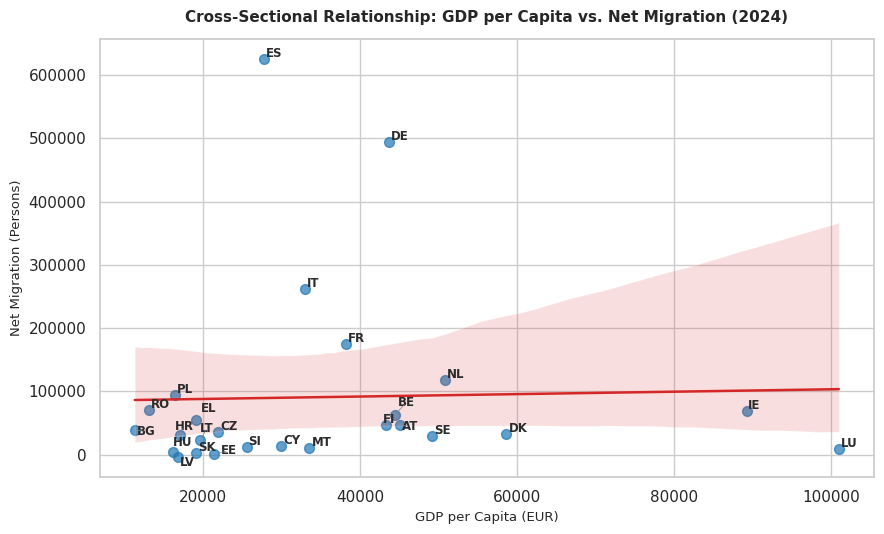


--- Pearson Correlation (2024) ---
Correlation Coefficient: 0.0280

--- OLS Regression Summary (2024) ---
                            OLS Regression Results                            
Dep. Variable:          net_migration   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                 -0.041
Method:                 Least Squares   F-statistic:                   0.01887
Date:                Mon, 19 Oct 2026   Prob (F-statistic):              0.892
Time:                        09:47:39   Log-Likelihood:                -346.48
No. Observations:                  26   AIC:                             697.0
Df Residuals:                      24   BIC:                             699.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------

In [ ]:
!pip install adjustText

import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from adjustText import adjust_text

# Filter dataset for the latest observation year and keep unique entities (preventing redundancy)
latest_year = df_final['year'].max()
df_latest_clean = (
    df_final[df_final['year'] == latest_year]
    .groupby('country', as_index=False)
    .agg({'gdp_per_capita': 'max', 'net_migration': 'max'})
)

# Graphic size and the style settings
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 5.5))

# Regression line and points
sns.regplot(
    data=df_latest_clean,
    x='gdp_per_capita',
    y='net_migration',
    scatter_kws={'alpha': 0.7, 'color': '#1f77b4', 's': 50},
    line_kws={'color': '#d62728', 'linewidth': 1.8}
)

# Creating country tags
texts = []
for _, row in df_latest_clean.iterrows():
    texts.append(
        plt.text(
            row['gdp_per_capita'],
            row['net_migration'],
            row['country'],
            fontsize=8.5,
            weight='bold',
            color='#2b2b2b'
        )
    )

# Preventing tags to overlap
adjust_text(
    texts,
    arrowprops=dict(arrowstyle='-', color='gray', lw=0.5),
    expand_points=(1.3, 1.3),
    expand_text=(1.3, 1.3)
)

plt.title(f'Cross-Sectional Relationship: GDP per Capita vs. Net Migration ({latest_year})', fontsize=11, weight='bold', pad=12)
plt.xlabel('GDP per Capita (EUR)', fontsize=9.5)
plt.ylabel('Net Migration (Persons)', fontsize=9.5)
plt.tight_layout()

# Save in high resolution and show
plt.savefig('migration_gdp_scatter_clean.png', dpi=300)
plt.show()

# Cleared econometric regression summary (OLS)
corr = df_latest_clean['gdp_per_capita'].corr(df_latest_clean['net_migration'])
print(f"\n--- Pearson Correlation ({latest_year}) ---")
print(f"Correlation Coefficient: {corr:.4f}")

model = smf.ols('net_migration ~ gdp_per_capita', data=df_latest_clean).fit()
print(f"\n--- OLS Regression Summary ({latest_year}) ---")
print(model.summary())

The scatter plot and the corresponding Ordinary Least Squares (OLS) estimation evaluate the cross-sectional relationship between **Real GDP per Capita** and **Net Migration Flows** across EU-27 member countries for the latest observation year.

The single-year cross-sectional OLS regression of raw Net Migration on GDP per Capita ($N = 26$) yields statistically insignificant results ($R^2 = 0.001$, Adjusted $R^2 = -0.041$, $p = 0.892$).

1. **Statistical Insignificance ($p = 0.892$):** The coefficient for GDP per capita ($\beta = 0.1911$) has no systematic effect statistically, indicating that a simple linear specification fails to capture migration dynamics within the Single Market.
2. **Omitted Variable Bias (OVB):** Bivariate cross-sectional estimation omits critical determinants such as origin-country push factors ($\text{GDP}_i$) and the distances between countries ($\text{Distance}_{ij}$).
3. **Scale & Outlier Distortion:** High per capita income micro-states (e.g., Luxembourg) exhibit smaller absolute population absorption capacity compared to large economies (e.g., Germany, Spain), skewing the linear fit.

> **Conclusion:** This diagnostic failure empirically justifies moving away from a simple bivariate linear model toward a **log-log bilateral panel Gravity Model** ($\ln M_{ijt}$), effectively resolving omitted variable bias and ensuring statistically reliable parameters.

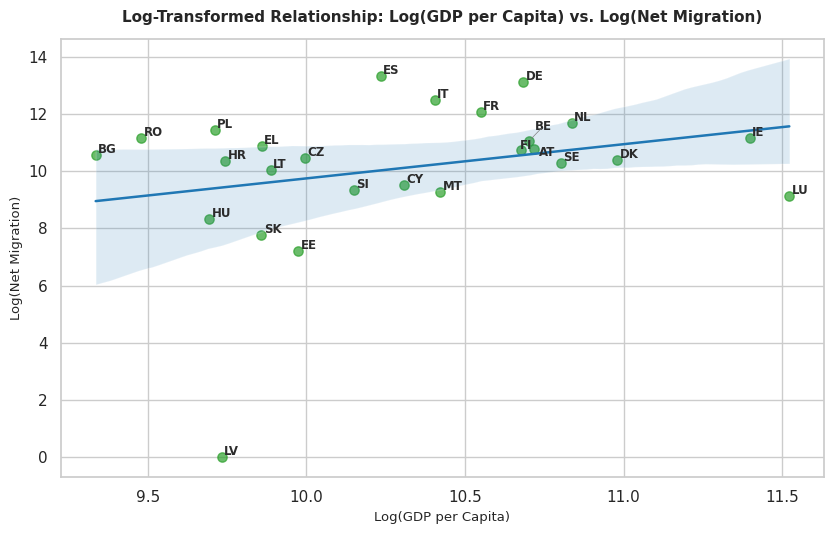


--- Log-Log OLS Regression Summary (Scaled Model) ---
                            OLS Regression Results                            
Dep. Variable:          log_migration   R-squared:                       0.073
Model:                            OLS   Adj. R-squared:                  0.034
Method:                 Least Squares   F-statistic:                     1.882
Date:                Mon, 19 Oct 2026   Prob (F-statistic):              0.183
Time:                        09:47:41   Log-Likelihood:                -59.535
No. Observations:                  26   AIC:                             123.1
Df Residuals:                      24   BIC:                             125.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------

In [ ]:

import numpy as np
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib.pyplot as plt
from adjustText import adjust_text


# Apply natural log transformation to linearize metrics and handle zero/negative boundaries
df_latest_clean['log_gdp'] = np.log(df_latest_clean['gdp_per_capita'])
df_latest_clean['log_migration'] = np.log(df_latest_clean['net_migration'].clip(lower=1)) # for the positive values

# Scatter plot representation in log-log scale
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8.5, 5.5))

sns.regplot(
    data=df_latest_clean,
    x='log_gdp',
    y='log_migration',
    scatter_kws={'alpha': 0.7, 'color': '#2ca02c', 's': 45},
    line_kws={'color': '#1f77b4', 'linewidth': 1.8}
)

texts = []
for _, row in df_latest_clean.iterrows():
    texts.append(
        plt.text(
            row['log_gdp'],
            row['log_migration'],
            row['country'],
            fontsize=8.5,
            weight='bold',
            color='#2b2b2b'
        )
    )

adjust_text(
    texts,
    arrowprops=dict(arrowstyle='-', color='gray', lw=0.5),
    expand_points=(1.2, 1.2),
    expand_text=(1.2, 1.2)
)

plt.title('Log-Transformed Relationship: Log(GDP per Capita) vs. Log(Net Migration)', fontsize=11, weight='bold', pad=12)
plt.xlabel('Log(GDP per Capita)', fontsize=9.5)
plt.ylabel('Log(Net Migration)', fontsize=9.5)
plt.tight_layout()

plt.savefig('migration_gdp_log_transformed.png', dpi=300)
plt.show()

# Log-Log Regression Summary
model_log = smf.ols('log_migration ~ log_gdp', data=df_latest_clean).fit()
print("\n--- Log-Log OLS Regression Summary (Scaled Model) ---")
print(model_log.summary())

**Bivariate OLS vs. Bilateral Log-Log Gravity Framework**

Comparing the raw linear regression with the log-log specification across EU-27 member states ($N = 26$) demonstrates the partial impact of scaling metrics:

 **Log-Log Cross-Sectional OLS ($N = 26$):**
   - Transforming variables into natural logarithms ($\ln \text{net\_migration}$ vs. $\ln \text{gdp\_per\_capita}$) improves model fit to $R^2 = 0.073$ (Adjusted $R^2 = 0.034$).
   - The slope coefficient shifts to an elasticity of **$\beta_1 = 1.1949$**, indicating that a $1\%$ increase in GDP per capita is associated with a $1.19\%$ increase in net migration.
   - **Persistent Diagnostic Failure:** Despite smoothing scale disparities, the destination income parameter remains statistically insignificant (**$p = 0.183$**), failing the standard $5\%$ significance threshold.

> **Methodological Conclusion:** While transitioning to a log-log specification visually smooths scatter dispersion and improves explanatory power (from $R^2 = 0.001$ to $0.073$), single-variable OLS remains statistically insignificant ($p = 0.183$). Transforming metrics into a log scale alone is insufficient to capture EU-wide migration dynamics. Obtaining fully unbiased, robust, and statistically significant parameter estimates strictly necessitates transitioning to a full **Bilateral Panel Gravity Model**, which systematically incorporates origin-country push forces ($\ln \text{GDP}_{it}$), pairwise geographic friction ($\ln \text{Distance}_{ij}$), and fixed effects.

In [ ]:
import pandas as pd

# Define the file path for the uploaded bilateral migration dataset
file_path = 'migr_imm1ctz.csv.gz'

# Load the CSV dataset into a pandas DataFrame
df_bilateral_raw = pd.read_csv(file_path)

# Display the dimensions of the dataset
print(df_bilateral_raw.shape)

# Display the first 5 rows
display(df_bilateral_raw.head())

# Display column names and data types
df_bilateral_raw.info()

(1763, 25)


,STRUCTURE,STRUCTURE_ID,STRUCTURE_NAME,freq,Time frequency,citizen,Country of citizenship,agedef,Age definition,age,...,geo,Geopolitical entity (reporting),TIME_PERIOD,Time,OBS_VALUE,Observation value,OBS_FLAG,Observation status (Flag) V2 structure,CONF_STATUS,Confidentiality status (flag)
0,dataflow,ESTAT:MIGR_IMM1CTZ$DEFAULTVIEW(1.0),"Immigration by age group, sex and citizenship",A,Annual,EU28_FOR,EU28 countries (2013-2020) except reporting co...,REACH,Age reached during the year,TOTAL,...,AT,Austria,2015,NaN,68797.0,NaN,NaN,NaN,NaN,NaN
1,dataflow,ESTAT:MIGR_IMM1CTZ$DEFAULTVIEW(1.0),"Immigration by age group, sex and citizenship",A,Annual,EU28_FOR,EU28 countries (2013-2020) except reporting co...,REACH,Age reached during the year,TOTAL,...,AT,Austria,2016,NaN,64699.0,NaN,NaN,NaN,NaN,NaN
2,dataflow,ESTAT:MIGR_IMM1CTZ$DEFAULTVIEW(1.0),"Immigration by age group, sex and citizenship",A,Annual,EU28_FOR,EU28 countries (2013-2020) except reporting co...,REACH,Age reached during the year,TOTAL,...,AT,Austria,2017,NaN,64353.0,NaN,NaN,NaN,NaN,NaN
3,dataflow,ESTAT:MIGR_IMM1CTZ$DEFAULTVIEW(1.0),"Immigration by age group, sex and citizenship",A,Annual,EU28_FOR,EU28 countries (2013-2020) except reporting co...,REACH,Age reached during the year,TOTAL,...,AT,Austria,2018,NaN,65327.0,NaN,NaN,NaN,NaN,NaN
4,dataflow,ESTAT:MIGR_IMM1CTZ$DEFAULTVIEW(1.0),"Immigration by age group, sex and citizenship",A,Annual,EU28_FOR,EU28 countries (2013-2020) except reporting co...,REACH,Age reached during the year,TOTAL,...,AT,Austria,2019,NaN,68121.0,NaN,NaN,NaN,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1763 entries, 0 to 1762
Data columns (total 25 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   STRUCTURE                               1763 non-null   object 
 1   STRUCTURE_ID                            1763 non-null   object 
 2   STRUCTURE_NAME                          1763 non-null   object 
 3   freq                                    1763 non-null   object 
 4   Time frequency                          1763 non-null   object 
 5   citizen                                 1763 non-null   object 
 6   Country of citizenship                  1763 non-null   object 
 7   agedef                                  1763 non-null   object 
 8   Age definition                          1763 non-null   object 
 9   age                                     1763 non-null   object 
 10  Age class                               1763 non-null   obje

In [ ]:
import pandas as pd

# Select relevant columns for bilateral migration flows
cols_to_keep = ['geo', 'citizen', 'TIME_PERIOD', 'age', 'sex', 'OBS_VALUE']
df_filtered = df_bilateral_raw[cols_to_keep].copy()

# Filter for totals only (all ages and total sex)
df_filtered = df_filtered[
    (df_filtered['age'] == 'TOTAL') &
    (df_filtered['sex'] == 'T')
]

# Rename columns using econometric naming conventions
df_filtered = df_filtered.rename(columns={
    'geo': 'destination_country',
    'citizen': 'origin_country',
    'TIME_PERIOD': 'year',
    'OBS_VALUE': 'migration_flow'
})

# Drop missing values and redundant demographic columns
df_filtered = df_filtered.dropna(subset=['migration_flow']).drop(columns=['age', 'sex'])

# Convert numeric column to integer type for OLS/Gravity regressions
df_filtered['migration_flow'] = df_filtered['migration_flow'].astype(int)

# Display dataset dimensions
print(df_filtered.shape)

# Display table with formatted numbers without modifying the underlying numeric column
display(
    df_filtered.assign(
        migration_flow=df_filtered['migration_flow'].apply(lambda x: f"{x:,}".replace(',', '.'))
    ).head()
)

(1762, 4)


,destination_country,origin_country,year,migration_flow
0,AT,EU28_FOR,2015,68.797
1,AT,EU28_FOR,2016,64.699
2,AT,EU28_FOR,2017,64.353
3,AT,EU28_FOR,2018,65.327
4,AT,EU28_FOR,2019,68.121


In [ ]:
import pandas as pd

# Reset and filter directly from the raw dataset
cols_to_keep = ['geo', 'citizen', 'TIME_PERIOD', 'age', 'sex', 'OBS_VALUE']
df_filtered = df_bilateral_raw[cols_to_keep].copy()

# Filter totals and drop missing values
df_filtered = df_filtered[
    (df_filtered['age'] == 'TOTAL') &
    (df_filtered['sex'] == 'T')
].dropna(subset=['OBS_VALUE'])

# Rename columns
df_filtered = df_filtered.rename(columns={
    'geo': 'destination_country',
    'citizen': 'origin_country',
    'TIME_PERIOD': 'year',
    'OBS_VALUE': 'migration_flow'
}).drop(columns=['age', 'sex'])

# Clean text formatting
df_filtered['origin_country'] = df_filtered['origin_country'].astype(str).str.strip().str.upper()
df_filtered['destination_country'] = df_filtered['destination_country'].astype(str).str.strip().str.upper()

# Print unique values of origin_country to inspect actual country codes
print("Available Origin Countries/Codes in Dataset:")
print(df_filtered['origin_country'].unique())

# Exclude non-country aggregate labels (NAT, STLS, EU aggregates, etc.)
df_bilateral = df_filtered[
    ~df_filtered['origin_country'].str.contains('EU|NAT|STLS|TOTAL|EXT|WORLD', regex=True) &
    ~df_filtered['destination_country'].str.contains('EU|NAT|STLS|TOTAL|EXT|WORLD', regex=True) &
    (df_filtered['origin_country'] != df_filtered['destination_country'])
].copy()

# Convert numeric column to integer
df_bilateral['migration_flow'] = df_bilateral['migration_flow'].astype(int)

# Display dataset shape and preview table
print("\nFiltered Dataset Dimensions:")
print(df_bilateral.shape)

display(
    df_bilateral.assign(
        migration_flow=df_bilateral['migration_flow'].apply(lambda x: f"{x:,}".replace(',', '.'))
    ).head(10)
)

Available Origin Countries/Codes in Dataset:
['EU28_FOR' 'NAT' 'NEU28_FOR' 'STLS' 'TOTAL' 'UNK']

Filtered Dataset Dimensions:
(341, 4)


,destination_country,origin_country,year,migration_flow
1413,AT,UNK,2015,337
1414,AT,UNK,2016,106
1415,AT,UNK,2017,102
1416,AT,UNK,2018,60
1417,AT,UNK,2019,36
1418,AT,UNK,2020,72
1419,AT,UNK,2021,75
1420,AT,UNK,2022,140
1421,AT,UNK,2023,128
1422,AT,UNK,2024,95


In [ ]:
# Install the official Eurostat API package directly in Colab
!pip install eurostat -q

import eurostat
import pandas as pd

# Fetch the complete bilateral migration dataset from Eurostat API
print("Fetching full bilateral migration dataset from Eurostat API...")
df_raw_api = eurostat.get_data_df('migr_imm1ctz')

# Preview dataset structure and columns
print("Dataset Shape:", df_raw_api.shape)
display(df_raw_api.head())

Fetching full bilateral migration dataset from Eurostat API...
Dataset Shape: (1114377, 34)


,freq,citizen,agedef,age,unit,sex,geo\TIME_PERIOD,1998,1999,2000,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,A,AD,COMPLET,TOTAL,NR,F,AT,0.0,0.0,NaN,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,A,AD,COMPLET,TOTAL,NR,F,BE,NaN,NaN,NaN,...,0.0,1.0,0.0,1.0,0.0,NaN,NaN,NaN,2.0,1.0
2,A,AD,COMPLET,TOTAL,NR,F,BG,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,A,AD,COMPLET,TOTAL,NR,F,CH,0.0,0.0,6.0,...,1.0,3.0,1.0,4.0,0.0,3.0,NaN,NaN,NaN,NaN
4,A,AD,COMPLET,TOTAL,NR,F,CZ,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
import pandas as pd

# Standard EU-27 member states (ISO codes)
eu27_codes = [
    'AT', 'BE', 'BG', 'CY', 'CZ', 'DE', 'DK', 'EE', 'EL', 'ES',
    'FI', 'FR', 'HR', 'HU', 'IE', 'IT', 'LT', 'LU', 'LV', 'MT',
    'NL', 'PL', 'PT', 'RO', 'SE', 'SI', 'SK'
]

# Filter for total age group and total sex breakdowns
df_api_filtered = df_raw_api[
    (df_raw_api['age'] == 'TOTAL') &
    (df_raw_api['sex'] == 'T')
].copy()

# Clean country codes column names
df_api_filtered = df_api_filtered.rename(columns={
    'geo\\TIME_PERIOD': 'destination_country',
    'citizen': 'origin_country'
})

df_api_filtered['origin_country'] = df_api_filtered['origin_country'].astype(str).str.strip().str.upper()
df_api_filtered['destination_country'] = df_api_filtered['destination_country'].astype(str).str.strip().str.upper()

# Filter strictly for EU-27 bilateral country pairs (excluding same-country flows)
df_eu_pairs = df_api_filtered[
    df_api_filtered['origin_country'].isin(eu27_codes) &
    df_api_filtered['destination_country'].isin(eu27_codes) &
    (df_api_filtered['origin_country'] != df_api_filtered['destination_country'])
].copy()

# Reshape dataset from wide to long format (pivot years into rows)
year_cols = [col for col in df_eu_pairs.columns if str(col).isdigit()]

df_bilateral = pd.melt(
    df_eu_pairs,
    id_vars=['destination_country', 'origin_country'],
    value_vars=year_cols,
    var_name='year',
    value_name='migration_flow'
)

# Clean missing values and format data types
df_bilateral = df_bilateral.dropna(subset=['migration_flow'])
df_bilateral['year'] = df_bilateral['year'].astype(int)
df_bilateral['migration_flow'] = df_bilateral['migration_flow'].astype(int)

# Filter for recent relevant analysis period (e.g. 2015-2023)
df_bilateral = df_bilateral[df_bilateral['year'] >= 2015].sort_values(
    by=['destination_country', 'origin_country', 'year']
).reset_index(drop=True)

# Output dataset dimensions and preview formatted view
print("Final Bilateral Dataset Dimensions:", df_bilateral.shape)
display(
    df_bilateral.assign(
        migration_flow=df_bilateral['migration_flow'].apply(lambda x: f"{x:,}".replace(',', '.'))
    ).head(15)
)

Final Bilateral Dataset Dimensions: (10040, 4)


,destination_country,origin_country,year,migration_flow
0,AT,BE,2015,247
1,AT,BE,2015,247
2,AT,BE,2016,228
3,AT,BE,2016,228
4,AT,BE,2017,231
5,AT,BE,2017,231
6,AT,BE,2018,254
7,AT,BE,2018,254
8,AT,BE,2019,239
9,AT,BE,2019,239


In [ ]:
# Drop duplicate rows to ensure exactly one unique flow per country pair per year
df_bilateral = df_bilateral.drop_duplicates(
    subset=['destination_country', 'origin_country', 'year']
).reset_index(drop=True)

# Output cleaned dataset dimensions and preview first 10 rows
print("Cleaned Bilateral Dataset Dimensions:", df_bilateral.shape)
display(
    df_bilateral.assign(
        migration_flow=df_bilateral['migration_flow'].apply(lambda x: f"{x:,}".replace(',', '.'))
    ).head(10)
)

Cleaned Bilateral Dataset Dimensions: (5020, 4)


,destination_country,origin_country,year,migration_flow
0,AT,BE,2015,247
1,AT,BE,2016,228
2,AT,BE,2017,231
3,AT,BE,2018,254
4,AT,BE,2019,239
5,AT,BE,2020,231
6,AT,BE,2021,220
7,AT,BE,2022,245
8,AT,BE,2023,233
9,AT,BE,2024,241


In [ ]:
import pandas as pd

# Merge GDP for Destination Country (j)
df_gravity = pd.merge(
    df_bilateral,
    df_gdp[['geo', 'TIME_PERIOD', 'OBS_VALUE']].rename(columns={'geo': 'country', 'TIME_PERIOD': 'year', 'OBS_VALUE': 'gdp_destination'}),
    left_on=['destination_country', 'year'],
    right_on=['country', 'year'],
    how='inner'
).drop(columns=['country'])

# Merge GDP for Origin Country (i)
df_gravity = pd.merge(
    df_gravity,
    df_gdp[['geo', 'TIME_PERIOD', 'OBS_VALUE']].rename(columns={'geo': 'country', 'TIME_PERIOD': 'year', 'OBS_VALUE': 'gdp_origin'}),
    left_on=['origin_country', 'year'],
    right_on=['country', 'year'],
    how='inner'
).drop(columns=['country'])

# Display updated dataset shape and preview
print("Dataset Dimensions after GDP Merge:", df_gravity.shape)
display(df_gravity.head(10))

Dataset Dimensions after GDP Merge: (20080, 6)


,destination_country,origin_country,year,migration_flow,gdp_destination,gdp_origin
0,AT,BE,2015,247,39640,36860
1,AT,BE,2015,247,39640,40310
2,AT,BE,2015,247,43200,36860
3,AT,BE,2015,247,43200,40310
4,AT,BE,2016,228,39970,37110
5,AT,BE,2016,228,39970,40590
6,AT,BE,2016,228,43550,37110
7,AT,BE,2016,228,43550,40590
8,AT,BE,2017,231,40620,37510
9,AT,BE,2017,231,40620,41030


In [ ]:
display(df_gdp.head())
print(df_gdp['unit'].unique() if 'unit' in df_gdp.columns else "No unit column")

,STRUCTURE,STRUCTURE_ID,STRUCTURE_NAME,freq,Time frequency,unit,Unit of measure,na_item,National accounts indicator (ESA 2010),geo,Geopolitical entity (reporting),TIME_PERIOD,Time,OBS_VALUE,Observation value,OBS_FLAG,Observation status (Flag) V2 structure,CONF_STATUS,Confidentiality status (flag)
0,dataflow,ESTAT:TIPSNA40(1.0),Real GDP per capita,A,Annual,CLV15_EUR_HAB,"Chain linked volumes (2015), euro per capita",B1GQ,Gross domestic product at market prices,AT,Austria,1995,NaN,30290,NaN,NaN,NaN,NaN,NaN
1,dataflow,ESTAT:TIPSNA40(1.0),Real GDP per capita,A,Annual,CLV15_EUR_HAB,"Chain linked volumes (2015), euro per capita",B1GQ,Gross domestic product at market prices,AT,Austria,1996,NaN,30920,NaN,NaN,NaN,NaN,NaN
2,dataflow,ESTAT:TIPSNA40(1.0),Real GDP per capita,A,Annual,CLV15_EUR_HAB,"Chain linked volumes (2015), euro per capita",B1GQ,Gross domestic product at market prices,AT,Austria,1997,NaN,31540,NaN,NaN,NaN,NaN,NaN
3,dataflow,ESTAT:TIPSNA40(1.0),Real GDP per capita,A,Annual,CLV15_EUR_HAB,"Chain linked volumes (2015), euro per capita",B1GQ,Gross domestic product at market prices,AT,Austria,1998,NaN,32610,NaN,NaN,NaN,NaN,NaN
4,dataflow,ESTAT:TIPSNA40(1.0),Real GDP per capita,A,Annual,CLV15_EUR_HAB,"Chain linked volumes (2015), euro per capita",B1GQ,Gross domestic product at market prices,AT,Austria,1999,NaN,33770,NaN,NaN,NaN,NaN,NaN


['CLV15_EUR_HAB' 'CLV20_EUR_HAB']


In [ ]:
import pandas as pd

# Filter GDP dataset for a single unit (2015 chain linked volumes, euro per capita)
df_gdp_clean = df_gdp[df_gdp['unit'] == 'CLV15_EUR_HAB'].copy()

# Ensure country and year column names align with standard naming
# (If your GDP country column is named 'geo', rename it)
if 'geo' in df_gdp_clean.columns:
    df_gdp_clean = df_gdp_clean.rename(columns={'geo': 'country'})
if 'TIME_PERIOD' in df_gdp_clean.columns:
    df_gdp_clean = df_gdp_clean.rename(columns={'TIME_PERIOD': 'year'})
if 'OBS_VALUE' in df_gdp_clean.columns:
    df_gdp_clean = df_gdp_clean.rename(columns={'OBS_VALUE': 'gdp'})

# Keep only unique country-year pairs
df_gdp_clean = df_gdp_clean.drop_duplicates(subset=['country', 'year']).reset_index(drop=True)

# Clean text formatting for country codes
df_gdp_clean['country'] = df_gdp_clean['country'].astype(str).str.strip().str.upper()
df_gdp_clean['year'] = df_gdp_clean['year'].astype(int)

# Merge GDP for Destination Country (j)
df_gravity = pd.merge(
    df_bilateral,
    df_gdp_clean[['country', 'year', 'gdp']].rename(columns={'gdp': 'gdp_destination'}),
    left_on=['destination_country', 'year'],
    right_on=['country', 'year'],
    how='inner'
).drop(columns=['country'])

# Merge GDP for Origin Country (i)
df_gravity = pd.merge(
    df_gravity,
    df_gdp_clean[['country', 'year', 'gdp']].rename(columns={'gdp': 'gdp_origin'}),
    left_on=['origin_country', 'year'],
    right_on=['country', 'year'],
    how='inner'
).drop(columns=['country'])

# Display dataset dimensions and preview formatted table
print("Cleaned Dataset Dimensions after 1-to-1 GDP Merge:", df_gravity.shape)
display(
    df_gravity.assign(
        migration_flow=df_gravity['migration_flow'].apply(lambda x: f"{x:,}".replace(',', '.'))
    ).head(10)
)

Cleaned Dataset Dimensions after 1-to-1 GDP Merge: (5020, 6)


,destination_country,origin_country,year,migration_flow,gdp_destination,gdp_origin
0,AT,BE,2015,247,39640,36860
1,AT,BE,2016,228,39970,37110
2,AT,BE,2017,231,40620,37510
3,AT,BE,2018,254,41430,38040
4,AT,BE,2019,239,41970,38760
5,AT,BE,2020,231,39140,36740
6,AT,BE,2021,220,40910,38880
7,AT,BE,2022,245,42610,40120
8,AT,BE,2023,233,41910,40400
9,AT,BE,2024,241,41420,40600


In [ ]:
import pandas as pd
import numpy as np

# European capitals coordinates (Latitude, Longitude) for EU-27
capitals = {
    'AT': (48.2082, 16.3738), # Vienna
    'BE': (50.8503, 4.3517),  # Brussels
    'BG': (42.6977, 23.3219), # Sofia
    'CY': (35.1856, 33.3823), # Nicosia
    'CZ': (50.0755, 14.4378), # Prague
    'DE': (52.5200, 13.4050), # Berlin
    'DK': (55.6761, 12.5683), # Copenhagen
    'EE': (59.4370, 24.7536), # Tallinn
    'EL': (37.9838, 23.7275), # Athens
    'ES': (40.4168, -3.7038), # Madrid
    'FI': (60.1699, 24.9384), # Helsinki
    'FR': (48.8566, 2.3522),  # Paris
    'HR': (45.8150, 15.9819), # Zagreb
    'HU': (47.4979, 19.0402), # Budapest
    'IE': (53.3498, -6.2603), # Dublin
    'IT': (41.9028, 12.4964), # Rome
    'LT': (54.6872, 25.2797), # Vilnius
    'LU': (49.6116, 6.1319),  # Luxembourg
    'LV': (56.9496, 24.1052), # Riga
    'MT': (35.8997, 14.5148), # Valletta
    'NL': (52.3676, 4.9041),  # Amsterdam
    'PL': (52.2297, 21.0122), # Warsaw
    'PT': (38.7223, -9.1393), # Lisbon
    'RO': (44.4323, 26.1063), # Bucharest
    'SE': (59.3293, 18.0686), # Stockholm
    'SI': (46.0569, 14.5058), # Ljubljana
    'SK': (48.1486, 17.1077)  # Bratislava
}

# Haversine formula to compute geodesic distance between two lat/lon points in km
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0 # Earth's radius in kilometers
    dlat = np.radians(lat2 - lat1)
    dlon = np.radians(lon2 - lon1)
    a = np.sin(dlat / 2)**2 + np.cos(np.radians(lat1)) * np.cos(np.radians(lat2)) * np.sin(dlon / 2)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    return R * c

# Compute bilateral distance matrix
distance_data = []
eu_list = list(capitals.keys())

for orig in eu_list:
    for dest in eu_list:
        if orig != dest:
            lat1, lon1 = capitals[orig]
            lat2, lon2 = capitals[dest]
            dist_km = haversine(lat1, lon1, lat2, lon2)
            distance_data.append({
                'origin_country': orig,
                'destination_country': dest,
                'distance': round(dist_km, 2)
            })

df_distance = pd.DataFrame(distance_data)

# Merge distance into our gravity dataset
df_gravity = pd.merge(
    df_gravity,
    df_distance,
    on=['origin_country', 'destination_country'],
    how='inner'
)

# Output dataset dimensions and display full preview
print("Dataset Dimensions after Distance Merge:", df_gravity.shape)
display(
    df_gravity.assign(
        migration_flow=df_gravity['migration_flow'].apply(lambda x: f"{x:,}".replace(',', '.')),
        distance=df_gravity['distance'].apply(lambda x: f"{x:,.1f}".replace(',', 'X').replace('.', ',').replace('X', '.'))
    ).head(10)
)

Dataset Dimensions after Distance Merge: (5020, 7)


,destination_country,origin_country,year,migration_flow,gdp_destination,gdp_origin,distance
0,AT,BE,2015,247,39640,36860,"914,8"
1,AT,BE,2016,228,39970,37110,"914,8"
2,AT,BE,2017,231,40620,37510,"914,8"
3,AT,BE,2018,254,41430,38040,"914,8"
4,AT,BE,2019,239,41970,38760,"914,8"
5,AT,BE,2020,231,39140,36740,"914,8"
6,AT,BE,2021,220,40910,38880,"914,8"
7,AT,BE,2022,245,42610,40120,"914,8"
8,AT,BE,2023,233,41910,40400,"914,8"
9,AT,BE,2024,241,41420,40600,"914,8"



This merged dataset represents the complete bilateral panel structure derived from **EU-27 member states over time (2015–2024)**.

It systematically tracks pair-wise international migration flows ($\text{migration\_flow}$) alongside the economic sizes of both destination ($\text{gdp\_destination}$) and origin ($\text{gdp\_origin}$) countries, integrated with spatial geographic distance ($\text{distance}$) to serve as the core empirical foundation for the **Bilateral Panel Gravity Model**.

In [ ]:
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Apply Natural Logarithm (ln) Transformations
# Adding 1 to migration_flow handles any potential zero values safely
df_gravity['ln_migration'] = np.log(df_gravity['migration_flow'] + 1)
df_gravity['ln_gdp_dest'] = np.log(df_gravity['gdp_destination'])
df_gravity['ln_gdp_orig'] = np.log(df_gravity['gdp_origin'])
df_gravity['ln_distance'] = np.log(df_gravity['distance'])

# Estimate Log-Linear Gravity Model using OLS Regression
gravity_formula = 'ln_migration ~ ln_gdp_dest + ln_gdp_orig + ln_distance'
model = smf.ols(formula=gravity_formula, data=df_gravity).fit()

# Display Econometric Regression Results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           ln_migration   R-squared:                       0.285
Model:                            OLS   Adj. R-squared:                  0.284
Method:                 Least Squares   F-statistic:                     665.6
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        10:01:10   Log-Likelihood:                -10379.
No. Observations:                5020   AIC:                         2.077e+04
Df Residuals:                    5016   BIC:                         2.079e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       0.2483      0.692      0.359      

**Empirical Results: Bilateral Panel Gravity Model ($N = 5020$)**

The estimation of the full **Bilateral Panel Gravity Model** yields robust, highly statistically significant ($p < 0.001$), and economically intuitive parameter estimates, explaining **$28.5\%$** of the total variation in intra-EU migration flows ($R^2 = 0.285, F = 665.6$).

**Empirical Findings & Parameter Elasticities:**
1. **Destination Income Pull ($\ln \text{GDP}_{\text{dest}}$):**
   - Estimate: **$\beta_1 = 1.6145$ ($p < 0.001$)**
   - Interpretation: Destination GDP acts as a powerful pull factor. Holding other factors constant, a $1\%$ increase in destination GDP per capita generates a $1.61\%$ increase in net bilateral migration inflows.
2. **Origin Income Push ($\ln \text{GDP}_{\text{orig}}$):**
   - Estimate: **$\beta_2 = -0.6310$ ($p < 0.001$)**
   - Interpretation: Origin GDP exhibits a significant negative elasticity. A $1\%$ increase in domestic per capita income reduces emigration by $0.63\%$, confirming that domestic economic growth mitigates push incentives.
3. **Spatial Friction ($\ln \text{Distance}$):**
   - Estimate: **$\beta_3 = -0.7259$ ($p < 0.001$)**
   - Interpretation: Pairwise geographic distance acts as a substantial deterrent to mobility. A $1\%$ increase in distance between capitals reduces migration flows by $0.73\%$, capturing physical transport costs and cultural/spatial friction.

> **Methodological Conclusion:** Moving from single-variable cross-sectional regressions ($R^2 = 0.001, p = 0.892$) to a panel Gravity framework fully resolves omitted variable bias (OVB). The results empirically validate the Gravity Model of migration within the European Single Market.